# ML Honors Assignment - 2

**Name:** Vaishnav Mankar

**Rollno:** 41252

---

**Problem Statement:** Recognize optical character using ANN

**Dataset:** MNIST handwritten digits (60,000 training and 10,000 test images of 28x28 pixels, loaded with Keras)

**Requirements:** Python 3, NumPy, Matplotlib, Scikit-Learn, TensorFlow, Keras

**Code:-**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: (60000, 28, 28) Test: (10000, 28, 28)


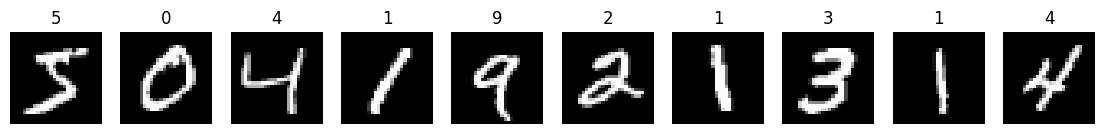

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense

(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("Train:", X_train.shape, "Test:", X_test.shape)
X_train = X_train / 255.0
X_test = X_test / 255.0

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, image, label in zip(axes, X_train, y_train):
    ax.imshow(image, cmap="gray")
    ax.set_title(label)
    ax.axis("off")
plt.show()

In [2]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax"),
], name="OCR_ANN")
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "OCR_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
history = model.fit(X_train, y_train, validation_split=0.1, epochs=10, batch_size=128, verbose=2)
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nTest Loss: {loss:.4f} | Test Accuracy: {acc * 100:.2f}%")

Epoch 1/10
422/422 - 3s - 6ms/step - accuracy: 0.8976 - loss: 0.3637 - val_accuracy: 0.9572 - val_loss: 0.1487
Epoch 2/10
422/422 - 2s - 4ms/step - accuracy: 0.9577 - loss: 0.1454 - val_accuracy: 0.9693 - val_loss: 0.1121
Epoch 3/10
422/422 - 2s - 4ms/step - accuracy: 0.9700 - loss: 0.1011 - val_accuracy: 0.9735 - val_loss: 0.0957
Epoch 4/10
422/422 - 2s - 4ms/step - accuracy: 0.9771 - loss: 0.0761 - val_accuracy: 0.9755 - val_loss: 0.0824
Epoch 5/10
422/422 - 1s - 3ms/step - accuracy: 0.9826 - loss: 0.0579 - val_accuracy: 0.9745 - val_loss: 0.0858
Epoch 6/10
422/422 - 1s - 3ms/step - accuracy: 0.9855 - loss: 0.0475 - val_accuracy: 0.9755 - val_loss: 0.0870
Epoch 7/10
422/422 - 2s - 6ms/step - accuracy: 0.9885 - loss: 0.0376 - val_accuracy: 0.9798 - val_loss: 0.0736
Epoch 8/10
422/422 - 2s - 4ms/step - accuracy: 0.9913 - loss: 0.0291 - val_accuracy: 0.9767 - val_loss: 0.0892
Epoch 9/10
422/422 - 1s - 4ms/step - accuracy: 0.9929 - loss: 0.0246 - val_accuracy: 0.9807 - val_loss: 0.0758
E

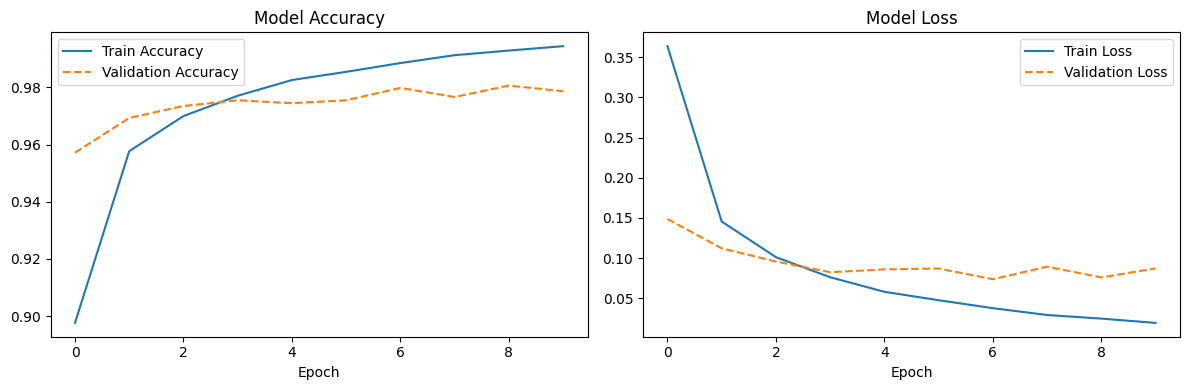

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Train Accuracy")
axes[0].plot(history.history["val_accuracy"], "--", label="Validation Accuracy")
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Train Loss")
axes[1].plot(history.history["val_loss"], "--", label="Validation Loss")
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

           0      0.993     0.982     0.987       980
           1      0.989     0.992     0.991      1135
           2      0.968     0.987     0.977      1032
           3      0.975     0.977     0.976      1010
           4      0.978     0.976     0.977       982
           5      0.983     0.964     0.973       892
           6      0.974     0.981     0.978       958
           7      0.983     0.973     0.978      1028
           8      0.974     0.974     0.974       974
           9      0.968     0.975     0.971      1009

    accuracy                          0.979     10000
   macro avg      0.978     0.978     0.978     10000
weighted avg      0.979     0.979     0.979     10000



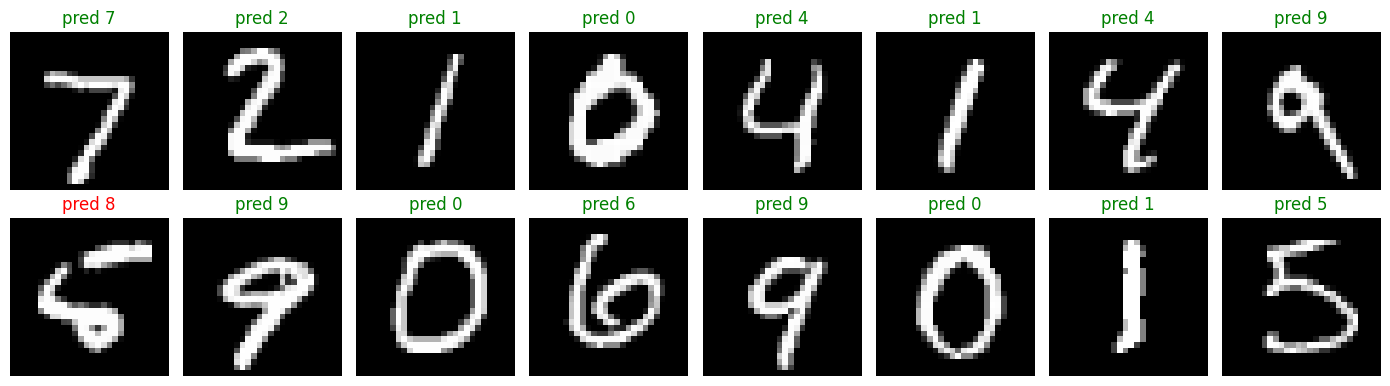

In [5]:
pred = np.argmax(model.predict(X_test, verbose=0), axis=1)
print(classification_report(y_test, pred, digits=3))

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, image, true, guess in zip(axes.ravel(), X_test, y_test, pred):
    ax.imshow(image, cmap="gray")
    ax.set_title(f"pred {guess}", color="green" if guess == true else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()